In [13]:
import pandas as pd
import numpy as np
import spacy
import re
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
DATA_DIR = Path("../data/processed")

sent_df = pd.read_csv(
    DATA_DIR / "segmented_sentences.csv"
)

sent_df["publication_date"] = pd.to_datetime(
    sent_df["publication_date"],
    errors="coerce"
)

print("Total sentences:", len(sent_df))

sent_df.head()

Total sentences: 25


,article_id,publication_date,sentence_id,sentence
0,article_01,2026-08-14,1,Continuous rainfall began across Riverton late...
1,article_01,2026-08-14,2,The city weather office recorded 118 millimetr...
2,article_01,2026-08-14,3,Emergency services received their first major ...
3,article_01,2026-08-14,4,Water entered ground-floor homes in the Rivers...
4,article_01,2026-08-14,5,The municipal corporation opened two temporary...


In [3]:
nlp = spacy.load("en_core_web_sm")

In [4]:
from spacy import displacy

test_sentence = "Police redirected traffic toward the North Bypass."

doc = nlp(test_sentence)

displacy.render(
    doc,
    style="dep",
    jupyter=True
)

In [5]:
def get_phrase(token):

    phrase_tokens = sorted(
        token.subtree,
        key=lambda t: t.i
    )

    return " ".join(
        t.text for t in phrase_tokens
        if not t.is_punct
    ).strip()

In [38]:
def get_phrase(token):
    """
    Extract a noun phrase while preserving its original meaning
    and normalizing whitespace.
    """

    if token.pos_ in ["NOUN", "PROPN", "PRON"]:

        phrase = token.doc[
            token.left_edge.i:token.right_edge.i + 1
        ].text

        return " ".join(phrase.split())

    return token.text.strip()


def get_subject(token):
    """
    Extract direct subjects and identify possible inherited
    subjects in coordinated and subordinate constructions.
    """

    subject_deps = {
        "nsubj",
        "nsubjpass",
        "nsubj:pass",
        "csubj",
        "csubj:pass"
    }

    subjects = [
        get_phrase(child)
        for child in token.children
        if child.dep_ in subject_deps
    ]

    # Handle coordinated predicates
    if not subjects and token.dep_ == "conj":

        subjects = [
            get_phrase(child)
            for child in token.head.children
            if child.dep_ in subject_deps
        ]

    # Handle subordinate clauses
    if not subjects and token.dep_ in ["advcl", "acl"]:

        subjects = [
            get_phrase(child)
            for child in token.head.children
            if child.dep_ in subject_deps
        ]

    # Handle open clausal complements
    if not subjects and token.dep_ == "xcomp":

        head = token.head

        # Check whether the governing predicate has an object
        # that can serve as the understood subject.
        subjects = [
            get_phrase(child)
            for child in head.children
            if child.dep_ in ["dobj", "obj", "nsubj", "nsubjpass"]
        ]

    return list(dict.fromkeys(subjects))


def get_objects(token):
    """
    Extract direct objects, indirect objects and complements.
    """

    object_deps = {
        "dobj",
        "obj",
        "dative",
        "attr",
        "oprd"
    }

    objects = [
        get_phrase(child)
        for child in token.children
        if child.dep_ in object_deps
    ]

    return list(dict.fromkeys(objects))


def get_agents(token):
    """
    Extract agents from passive constructions.
    """

    agents = []

    for child in token.children:

        if child.dep_ in ["agent", "obl:agent"]:

            for agent_child in child.children:

                if agent_child.dep_ == "pobj":
                    agents.append(get_phrase(agent_child))

    return list(dict.fromkeys(agents))


def is_event_candidate(token):
    """
    Identify potential event predicates using POS and
    dependency information.
    """

    # Finite and non-finite verbs
    if token.pos_ == "VERB":
        return True

    # Clausal complements can represent events even when
    # the parser assigns an unexpected POS tag.
    if token.dep_ in ["xcomp", "ccomp", "advcl", "acl"]:

        if token.pos_ in ["VERB", "AUX", "NOUN"]:
            return True

    return False

In [39]:
def extract_events(sentence):

    doc = nlp(sentence)
    events = []

    # ---------------------------------
    # 1. Temporal entities
    # ---------------------------------

    temporal_entities = list(dict.fromkeys(
        ent.text for ent in doc.ents
        if ent.label_ in ["DATE", "TIME"]
    ))

    # ---------------------------------
    # 2. Location entities
    # ---------------------------------

    locations = set()

    for ent in doc.ents:

        if ent.label_ in ["GPE", "LOC", "FAC"]:
            locations.add(ent.text)

    location_prepositions = {
        "in", "at", "near", "across",
        "from", "inside", "outside",
        "into", "towards", "through"
    }

    for token in doc:

        if token.dep_ == "prep" and token.text.lower() in location_prepositions:

            for child in token.children:

                if child.dep_ != "pobj":
                    continue

                if child.like_num:
                    continue

                # Exclude temporal entities
                if any(
                    child == ent.root
                    for ent in doc.ents
                    if ent.label_ in ["DATE", "TIME"]
                ):
                    continue

                locations.add(get_phrase(child))

                for conj in child.conjuncts:
                    locations.add(get_phrase(conj))

    location_entities = sorted(locations)

    # ---------------------------------
    # 3. Event extraction
    # ---------------------------------

    for token in doc:

        if not is_event_candidate(token):
            continue

        subject = get_subject(token)
        obj = get_objects(token)
        agent = get_agents(token)

        # ---------------------------------
        # 4. Passive voice
        # ---------------------------------

        passive = any(
            child.dep_ in ["nsubjpass", "nsubj:pass"]
            for child in token.children
        )

        # ---------------------------------
        # 5. Negation
        # ---------------------------------

        negation = any(
            child.dep_ == "neg"
            for child in token.children
        )

        # ---------------------------------
        # 6. Event representation
        # ---------------------------------

        events.append({

            "event_trigger": token.text,

            "action": token.lemma_,

            "subject": " | ".join(subject),

            "object": " | ".join(obj),

            "agent": " | ".join(agent),

            "passive": passive,

            "negation": negation,

            "temporal_entities": temporal_entities,

            "location_entities": location_entities

        })

    return events

In [40]:
test_sentence = """
Continuous rainfall began across Riverton late on August 13,
causing several streets in the eastern part of the city to flood
by early Friday morning.
"""

results = extract_events(test_sentence)

display(pd.DataFrame(results))

,event_trigger,action,subject,object,agent,passive,negation,temporal_entities,location_entities
0,began,begin,Continuous rainfall,,,False,False,"[August 13, early Friday, morning]","[Riverton, the eastern part of the city]"
1,causing,cause,Continuous rainfall,several streets in the eastern part of the city,,False,False,"[August 13, early Friday, morning]","[Riverton, the eastern part of the city]"
2,flood,flood,several streets in the eastern part of the city,,,False,False,"[August 13, early Friday, morning]","[Riverton, the eastern part of the city]"


In [37]:
doc = nlp(test_sentence)

for token in doc:
    print(
        f"{token.text:15}",
        f"POS: {token.pos_:10}",
        f"DEP: {token.dep_:12}",
        f"HEAD: {token.head.text}"
    )


               POS: SPACE      DEP: dep          HEAD: rainfall
Continuous      POS: ADJ        DEP: amod         HEAD: rainfall
rainfall        POS: NOUN       DEP: nsubj        HEAD: began
began           POS: VERB       DEP: ROOT         HEAD: began
across          POS: ADP        DEP: prep         HEAD: began
Riverton        POS: PROPN      DEP: pobj         HEAD: across
late            POS: ADV        DEP: advmod       HEAD: began
on              POS: ADP        DEP: prep         HEAD: began
August          POS: PROPN      DEP: pobj         HEAD: on
13              POS: NUM        DEP: nummod       HEAD: August
,               POS: PUNCT      DEP: punct        HEAD: began

               POS: SPACE      DEP: dep          HEAD: ,
causing         POS: VERB       DEP: advcl        HEAD: began
several         POS: ADJ        DEP: amod         HEAD: streets
streets         POS: NOUN       DEP: dobj         HEAD: causing
in              POS: ADP        DEP: prep         HEAD: streets
t

In [41]:
event_records = []

for _, row in sent_df.iterrows():

    extracted_events = extract_events(row["sentence"])

    for event in extracted_events:

        event_records.append({

            "article_id": row["article_id"],
            "sentence_id": row["sentence_id"],
            "publication_date": row["publication_date"],
            "original_sentence": row["sentence"],

            **event

        })

events_df = pd.DataFrame(event_records)

print("Total extracted events:", len(events_df))

events_df.head(20)

Total extracted events: 52


,article_id,sentence_id,publication_date,original_sentence,event_trigger,action,subject,object,agent,passive,negation,temporal_entities,location_entities
0,article_01,1,2026-08-14,"Continuous rainfall began across Riverton late on August 13, causing several streets in the eastern part of the city to flood by early Friday morning.",began,begin,Continuous rainfall,,,False,False,"[August 13, early Friday, morning]","[Riverton, the eastern part of the city]"
1,article_01,1,2026-08-14,"Continuous rainfall began across Riverton late on August 13, causing several streets in the eastern part of the city to flood by early Friday morning.",causing,cause,Continuous rainfall,,,False,False,"[August 13, early Friday, morning]","[Riverton, the eastern part of the city]"
2,article_01,1,2026-08-14,"Continuous rainfall began across Riverton late on August 13, causing several streets in the eastern part of the city to flood by early Friday morning.",flood,flood,several streets in the eastern part of the city,,,False,False,"[August 13, early Friday, morning]","[Riverton, the eastern part of the city]"
3,article_01,2,2026-08-14,The city weather office recorded 118 millimetres of rain in twelve hours.,recorded,record,The city weather office,118 millimetres of rain,,False,False,[twelve hours],[]
4,article_01,3,2026-08-14,Emergency services received their first major flooding calls at approximately 5:30 a.m. on August 14.,received,receive,Emergency services,their first major flooding calls,,False,False,"[approximately 5:30 a.m., August 14]",[]
5,article_01,4,2026-08-14,"Water entered ground-floor homes in the Riverside neighbourhood, and traffic was diverted from the Old Bridge.",entered,enter,Water,ground-floor homes,,False,False,[],"[the Old Bridge, the Riverside neighbourhood]"
6,article_01,4,2026-08-14,"Water entered ground-floor homes in the Riverside neighbourhood, and traffic was diverted from the Old Bridge.",diverted,divert,traffic,,,True,False,[],"[the Old Bridge, the Riverside neighbourhood]"
7,article_01,5,2026-08-14,The municipal corporation opened two temporary shelters at Central High School and the Riverside Community Hall.,opened,open,The municipal corporation,two temporary shelters,,False,False,[],"[Central High School and the Riverside Community Hall, the Riverside Community Hall]"
8,article_01,6,2026-08-14,Officials said that 46 residents had been moved to the shelters by 10 a.m.,said,say,Officials,,,False,False,[10 a.m.],[]
9,article_01,6,2026-08-14,Officials said that 46 residents had been moved to the shelters by 10 a.m.,moved,move,46 residents,,,True,False,[10 a.m.],[]


In [44]:
OUTPUT_DIR = Path("../data/processed")

events_df.to_csv(
    OUTPUT_DIR / "extracted_events.csv",
    index=False
)

print("Event extraction results saved!")

Event extraction results saved!


In [10]:
pd.set_option("display.max_colwidth", 100)

events_df[[
    "article_id",
    "original_sentence",
    "event_trigger",
    "subject",
    "action",
    "object"
]].head(30)

,article_id,original_sentence,event_trigger,subject,action,object
0,article_01,"Continuous rainfall began across Riverton late on August 13, causing several streets in the east...",began,Continuous rainfall,begin,
1,article_01,"Continuous rainfall began across Riverton late on August 13, causing several streets in the east...",causing,,cause,
2,article_01,"Continuous rainfall began across Riverton late on August 13, causing several streets in the east...",flood,several streets in the eastern part of the city,flood,
3,article_01,The city weather office recorded 118 millimetres of rain in twelve hours.,recorded,The city weather office,record,118 millimetres of rain
4,article_01,Emergency services received their first major flooding calls at approximately 5:30 a.m. on Augus...,received,Emergency services,receive,their first major flooding calls
5,article_01,"Water entered ground-floor homes in the Riverside neighbourhood, and traffic was diverted from t...",entered,Water,enter,ground floor homes
6,article_01,"Water entered ground-floor homes in the Riverside neighbourhood, and traffic was diverted from t...",diverted,traffic,divert,
7,article_01,The municipal corporation opened two temporary shelters at Central High School and the Riverside...,opened,The municipal corporation,open,two temporary shelters
8,article_01,Officials said that 46 residents had been moved to the shelters by 10 a.m.,said,Officials,say,
9,article_01,Officials said that 46 residents had been moved to the shelters by 10 a.m.,moved,46 residents,move,


In [11]:
print("Total extracted events:", len(events_df))

print("\nMissing component analysis:")

for col in ["subject", "action", "object"]:
    missing = events_df[col].isna().sum() + (
        events_df[col].astype(str).str.strip() == ""
    ).sum()

    print(f"{col}: {missing}")

Total extracted events: 52

Missing component analysis:
subject: 10
action: 0
object: 36


article_id
article_01    14
article_02    17
article_03    21
dtype: int64


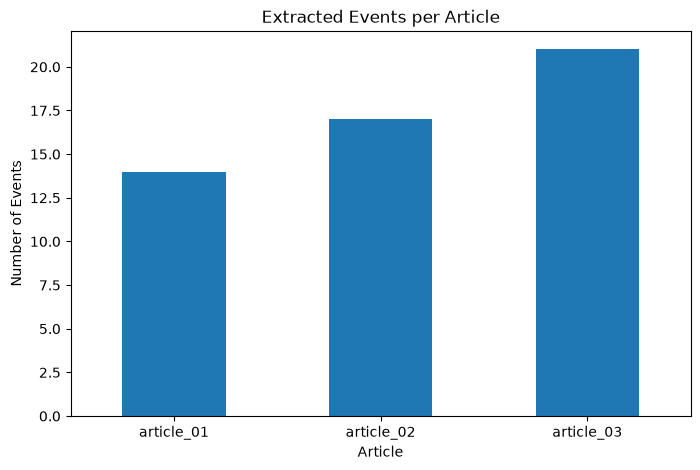

In [14]:
event_counts = events_df.groupby("article_id").size()

print(event_counts)

event_counts.plot(
    kind="bar",
    title="Extracted Events per Article",
    figsize=(8, 5)
)

plt.ylabel("Number of Events")
plt.xlabel("Article")
plt.xticks(rotation=0)
plt.show()

In [15]:
for _, row in events_df.iterrows():

    print("\nSentence:", row["original_sentence"])
    print("Subject:", row["subject"])
    print("Action:", row["action"])
    print("Object:", row["object"])
    print("-" * 70)


Sentence: Continuous rainfall began across Riverton late on August 13, causing several streets in the eastern part of the city to flood by early Friday morning.
Subject: Continuous rainfall
Action: begin
Object: 
----------------------------------------------------------------------

Sentence: Continuous rainfall began across Riverton late on August 13, causing several streets in the eastern part of the city to flood by early Friday morning.
Subject: 
Action: cause
Object: 
----------------------------------------------------------------------

Sentence: Continuous rainfall began across Riverton late on August 13, causing several streets in the eastern part of the city to flood by early Friday morning.
Subject: several streets in the eastern part of the city
Action: flood
Object: 
----------------------------------------------------------------------

Sentence: The city weather office recorded 118 millimetres of rain in twelve hours.
Subject: The city weather office
Action: record
Obj

In [16]:
from spacy import displacy

test_sentence = (
    "Continuous rainfall began across Riverton late on August 13, "
    "causing several streets in the eastern part of the city to flood "
    "by early Friday morning."
)

doc = nlp(test_sentence)

for token in doc:
    print(
        f"{token.text:<18} "
        f"{token.pos_:<10} "
        f"{token.dep_:<12} "
        f"Head: {token.head.text}"
    )

displacy.render(doc, style="dep", jupyter=True)

Continuous         ADJ        amod         Head: rainfall
rainfall           NOUN       nsubj        Head: began
began              VERB       ROOT         Head: began
across             ADP        prep         Head: began
Riverton           PROPN      pobj         Head: across
late               ADV        advmod       Head: began
on                 ADP        prep         Head: began
August             PROPN      pobj         Head: on
13                 NUM        nummod       Head: August
,                  PUNCT      punct        Head: began
causing            VERB       advcl        Head: began
several            ADJ        amod         Head: streets
streets            NOUN       nsubj        Head: flood
in                 ADP        prep         Head: streets
the                DET        det          Head: part
eastern            ADJ        amod         Head: part
part               NOUN       pobj         Head: in
of                 ADP        prep         Head: part
the       

In [17]:
print("Total events:", len(events_df))

print("\nColumns:")
print(events_df.columns.tolist())

print("\nMissing values:")
print(events_df.isnull().sum())

display(events_df.head(10))

Total events: 52

Columns:
['article_id', 'sentence_id', 'publication_date', 'original_sentence', 'event_trigger', 'action', 'subject', 'object', 'negation', 'temporal_entities', 'location_entities']

Missing values:
article_id           0
sentence_id          0
publication_date     0
original_sentence    0
event_trigger        0
action               0
subject              0
object               0
negation             0
temporal_entities    0
location_entities    0
dtype: int64


,article_id,sentence_id,publication_date,original_sentence,event_trigger,action,subject,object,negation,temporal_entities,location_entities
0,article_01,1,2026-08-14,"Continuous rainfall began across Riverton late on August 13, causing several streets in the east...",began,begin,Continuous rainfall,,False,"[August 13, early Friday, morning]",[Riverton]
1,article_01,1,2026-08-14,"Continuous rainfall began across Riverton late on August 13, causing several streets in the east...",causing,cause,,,False,"[August 13, early Friday, morning]",[Riverton]
2,article_01,1,2026-08-14,"Continuous rainfall began across Riverton late on August 13, causing several streets in the east...",flood,flood,several streets in the eastern part of the city,,False,"[August 13, early Friday, morning]",[Riverton]
3,article_01,2,2026-08-14,The city weather office recorded 118 millimetres of rain in twelve hours.,recorded,record,The city weather office,118 millimetres of rain,False,[twelve hours],[]
4,article_01,3,2026-08-14,Emergency services received their first major flooding calls at approximately 5:30 a.m. on Augus...,received,receive,Emergency services,their first major flooding calls,False,"[approximately 5:30 a.m., August 14]",[]
5,article_01,4,2026-08-14,"Water entered ground-floor homes in the Riverside neighbourhood, and traffic was diverted from t...",entered,enter,Water,ground floor homes,False,[],[the Old Bridge]
6,article_01,4,2026-08-14,"Water entered ground-floor homes in the Riverside neighbourhood, and traffic was diverted from t...",diverted,divert,traffic,,False,[],[the Old Bridge]
7,article_01,5,2026-08-14,The municipal corporation opened two temporary shelters at Central High School and the Riverside...,opened,open,The municipal corporation,two temporary shelters,False,[],[]
8,article_01,6,2026-08-14,Officials said that 46 residents had been moved to the shelters by 10 a.m.,said,say,Officials,,False,[10 a.m.],[]
9,article_01,6,2026-08-14,Officials said that 46 residents had been moved to the shelters by 10 a.m.,moved,move,46 residents,,False,[10 a.m.],[]


In [42]:
pd.set_option("display.max_colwidth", None)

display(
    events_df[
        [
            "original_sentence",
            "event_trigger",
            "action",
            "subject",
            "object",
            "negation",
            "temporal_entities",
            "location_entities"
        ]
    ].head(15)
)

,original_sentence,event_trigger,action,subject,object,negation,temporal_entities,location_entities
0,"Continuous rainfall began across Riverton late on August 13, causing several streets in the eastern part of the city to flood by early Friday morning.",began,begin,Continuous rainfall,,False,"[August 13, early Friday, morning]","[Riverton, the eastern part of the city]"
1,"Continuous rainfall began across Riverton late on August 13, causing several streets in the eastern part of the city to flood by early Friday morning.",causing,cause,Continuous rainfall,,False,"[August 13, early Friday, morning]","[Riverton, the eastern part of the city]"
2,"Continuous rainfall began across Riverton late on August 13, causing several streets in the eastern part of the city to flood by early Friday morning.",flood,flood,several streets in the eastern part of the city,,False,"[August 13, early Friday, morning]","[Riverton, the eastern part of the city]"
3,The city weather office recorded 118 millimetres of rain in twelve hours.,recorded,record,The city weather office,118 millimetres of rain,False,[twelve hours],[]
4,Emergency services received their first major flooding calls at approximately 5:30 a.m. on August 14.,received,receive,Emergency services,their first major flooding calls,False,"[approximately 5:30 a.m., August 14]",[]
5,"Water entered ground-floor homes in the Riverside neighbourhood, and traffic was diverted from the Old Bridge.",entered,enter,Water,ground-floor homes,False,[],"[the Old Bridge, the Riverside neighbourhood]"
6,"Water entered ground-floor homes in the Riverside neighbourhood, and traffic was diverted from the Old Bridge.",diverted,divert,traffic,,False,[],"[the Old Bridge, the Riverside neighbourhood]"
7,The municipal corporation opened two temporary shelters at Central High School and the Riverside Community Hall.,opened,open,The municipal corporation,two temporary shelters,False,[],"[Central High School and the Riverside Community Hall, the Riverside Community Hall]"
8,Officials said that 46 residents had been moved to the shelters by 10 a.m.,said,say,Officials,,False,[10 a.m.],[]
9,Officials said that 46 residents had been moved to the shelters by 10 a.m.,moved,move,46 residents,,False,[10 a.m.],[]


In [24]:
test_sentences = [
    "Continuous rainfall began across Riverton late on August 13, causing several streets in the eastern part of the city to flood by early Friday morning.",

    "Water entered ground-floor homes in the Riverside neighbourhood, and traffic was diverted from the Old Bridge.",

    "The municipal corporation opened two temporary shelters at Central High School and the Riverside Community Hall."
]

for sentence in test_sentences:

    doc = nlp(sentence)

    print("\n" + "="*100)
    print(sentence)
    print("="*100)

    for token in doc:

        print(
            f"{token.text:<18}"
            f"{token.pos_:<10}"
            f"{token.dep_:<15}"
            f"Head: {token.head.text:<15}"
        )


Continuous rainfall began across Riverton late on August 13, causing several streets in the eastern part of the city to flood by early Friday morning.
Continuous        ADJ       amod           Head: rainfall       
rainfall          NOUN      nsubj          Head: began          
began             VERB      ROOT           Head: began          
across            ADP       prep           Head: began          
Riverton          PROPN     pobj           Head: across         
late              ADV       advmod         Head: began          
on                ADP       prep           Head: began          
August            PROPN     pobj           Head: on             
13                NUM       nummod         Head: August         
,                 PUNCT     punct          Head: began          
causing           VERB      advcl          Head: began          
several           ADJ       amod           Head: streets        
streets           NOUN      nsubj          Head: flood          
in 

In [43]:
sample_sentences = (
    events_df[["article_id", "sentence_id", "original_sentence"]]
    .drop_duplicates()
    .head(10)
)

for _, row in sample_sentences.iterrows():

    doc = nlp(row["original_sentence"])

    print("\nSentence:", row["original_sentence"])

    print("Temporal entities:")

    for ent in doc.ents:
        if ent.label_ in ["DATE", "TIME"]:
            print(ent.text, "->", ent.label_)


Sentence: Continuous rainfall began across Riverton late on August 13, causing several streets in the eastern part of the city to flood by early Friday morning.
Temporal entities:
August 13 -> DATE
early Friday -> DATE
morning -> TIME

Sentence: The city weather office recorded 118 millimetres of rain in twelve hours.
Temporal entities:
twelve hours -> TIME

Sentence: Emergency services received their first major flooding calls at approximately 5:30 a.m. on August 14.
Temporal entities:
approximately 5:30 a.m. -> TIME
August 14 -> DATE

Sentence: Water entered ground-floor homes in the Riverside neighbourhood, and traffic was diverted from the Old Bridge.
Temporal entities:

Sentence: The municipal corporation opened two temporary shelters at Central High School and the Riverside Community Hall.
Temporal entities:

Sentence: Officials said that 46 residents had been moved to the shelters by 10 a.m.
Temporal entities:
10 a.m. -> TIME

Sentence: The weather office warned that further ra